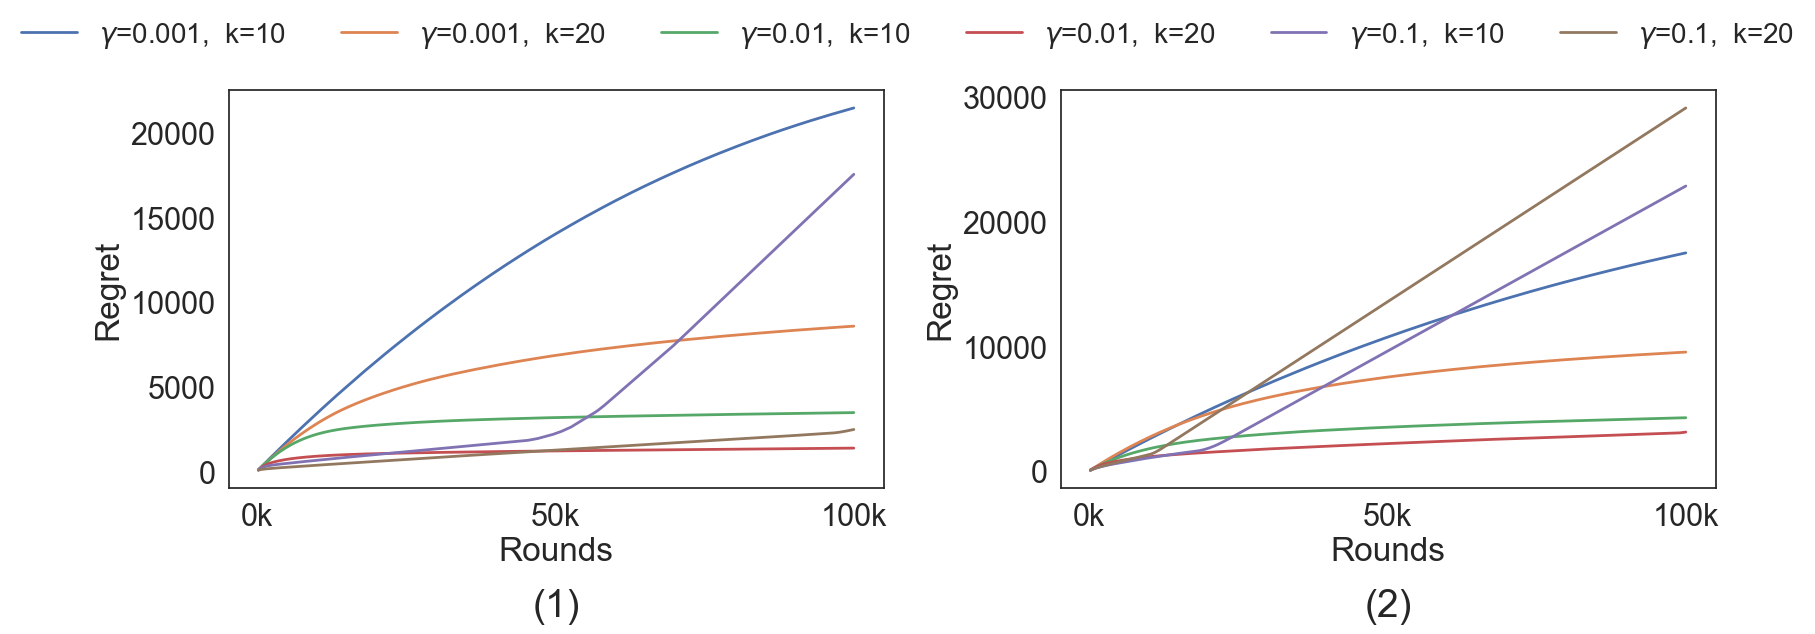

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns


def analyze_gamma_effect(l_df, s_df, T=100000, sample_step=200):
    valid_gammas = ['0.1', '0.01', '0.001']

    for df in [l_df, s_df]:
        df['gamma'] = df['gamma'].astype(str)
        df['k'] = df['k'].astype(int)
        df['algorithm'] = 'EXP3.M'

    # Filter
    l_df = l_df[l_df['gamma'].isin(valid_gammas)]
    s_df = s_df[s_df['gamma'].isin(valid_gammas)]

    sns.set_theme(style="white", font_scale=2)
    fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharex=True)

    for ax, phase_df, title in zip(
        axes,
        [l_df[l_df['t'] <= T], s_df[s_df['t'] <= T]],
        ["Large-scale (L)", "Small-scale (S)"]   # 不再使用 title
    ):

        # ---- 聚合 ----
        phase_df = (
            phase_df.groupby(["t", "gamma", "k"], as_index=False)["regret"]
            .mean()
        )

        # ---- 降采样 ----
        phase_df = phase_df[phase_df["t"] % sample_step == 0]

        # ---- 手动画图 ----
        for (g, k), df2 in phase_df.groupby(["gamma", "k"]):
            ax.plot(
                df2["t"],
                df2["regret"],
                linewidth=2,
                label=f"$\\gamma$={g},  k={k}"
            )

        ax.set_xlabel("Rounds")
        ax.set_ylabel("Regret")
        ax.set_xticks([0, 50000, 100000])
        ax.xaxis.set_major_formatter(
            ticker.FuncFormatter(lambda x, _: f"{int(x/1000)}k")
        )
        # ax.set_title(title)   # ← **已移除标题**
        ax.grid(False)

    # ---- Legend（6 个一行） ----
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles, labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 1),
        ncol=6,
        frameon=False,
        prop={"size": 20},
    )

    # Subfigure labels
    axes[0].text(0.5, -0.25, "(1)", ha="center", va="top",
                 transform=axes[0].transAxes, fontsize=28)
    axes[1].text(0.5, -0.25, "(2)", ha="center", va="top",
                 transform=axes[1].transAxes, fontsize=28)

    fig.tight_layout(rect=[0, 0, 1, 0.92])

    fig.savefig("exp3m_gamma_k_regret_dual_clean.png", dpi=300, bbox_inches="tight")
    fig.savefig("exp3m_gamma_k_regret_dual_clean.pdf", bbox_inches="tight")
    plt.show()


# ---------------------
#     MAIN FUNCTION
# ---------------------
if __name__ == "__main__":
    l_conv_gamma = pd.read_csv("results/l_conv_gamma.csv")
    s_conv_gamma = pd.read_csv("results/s_conv_gamma.csv")

    analyze_gamma_effect(l_conv_gamma, s_conv_gamma)



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from matplotlib.transforms import Bbox
import os

def analyze_gamma_effect(l_df, s_df, T=100000, sample_step=200):
    os.makedirs("split_figs", exist_ok=True)

    valid_gammas = ['0.1', '0.01', '0.001']

    for df in [l_df, s_df]:
        df['gamma'] = df['gamma'].astype(str)
        df['k'] = df['k'].astype(int)
        df['algorithm'] = 'EXP3.M'

    l_df = l_df[l_df['gamma'].isin(valid_gammas)]
    s_df = s_df[s_df['gamma'].isin(valid_gammas)]

    sns.set_theme(style="white", font_scale=2)
    fig, axes = plt.subplots(1, 2, figsize=(17, 5), sharex=True)

    for ax, phase_df in zip(
        axes,
        [l_df[l_df['t'] <= T], s_df[s_df['t'] <= T]]
    ):
        # ===== 聚合 =====
        phase_df = (
            phase_df.groupby(["t", "gamma", "k"], as_index=False)["regret"]
            .mean()
        )

        # ===== 降采样 =====
        phase_df = phase_df[phase_df["t"] % sample_step == 0]

        # ===== 伸缩坐标（关键改动）=====
        phase_df["t_scaled"] = phase_df["t"] / 1e4
        phase_df["regret_scaled"] = phase_df["regret"] / 1e4

        for (g, k), df2 in phase_df.groupby(["gamma", "k"]):
            ax.plot(
                df2["t_scaled"],
                df2["regret_scaled"],
                linewidth=2,
                label=f"$\\gamma$={g},\\ k={k}"
            )

        ax.set_xlabel("Rounds ($\\times 10^4$)")
        ax.set_ylabel("Regret ($\\times 10^4$)")
        ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
        ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=3))
        ax.grid(False)

    # ===== 布局 & 渲染 =====
    fig.tight_layout()
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    # ===================== 裁剪并导出两个子图 =====================
    for i, ax in enumerate(axes):
        bbox = ax.get_tightbbox(renderer).transformed(
            fig.dpi_scale_trans.inverted()
        )
        bbox = bbox.expanded(1.05, 1.10)

        fig.savefig(
            f"split_figs/gamma_subplot_{i+1}.pdf",
            bbox_inches=bbox, pad_inches=0.02
        )
        fig.savefig(
            f"split_figs/gamma_subplot_{i+1}.png",
            bbox_inches=bbox, pad_inches=0.02, dpi=600
        )

    # ===================== 单独导出 legend =====================
    handles, labels = axes[0].get_legend_handles_labels()

    fig_leg = plt.figure(figsize=(14, 2))
    fig_leg.legend(
        handles, labels,
        loc="center",
        ncol=6,
        frameon=False,
        prop={"size": 20}
    )

    fig_leg.savefig("split_figs/gamma_legend.pdf", bbox_inches="tight")
    fig_leg.savefig("split_figs/gamma_legend.png", bbox_inches="tight", dpi=600)

    plt.close(fig_leg)
    plt.close(fig)


# ---------------------
#     MAIN FUNCTION
# ---------------------
if __name__ == "__main__":
    l_conv_gamma = pd.read_csv("results/l_conv_gamma.csv")
    s_conv_gamma = pd.read_csv("results/s_conv_gamma.csv")

    analyze_gamma_effect(l_conv_gamma, s_conv_gamma)

